In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from imblearn import FunctionSampler
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC, SVC
from xgboost import XGBClassifier

RANDOM_STATE = 42
OUTER_FOLDS, OUTER_REPEATS, INNER_FOLDS = 5, 2, 5
N_JOBS = 1
DATASET = Path("Datasets/Processed/Dataset Dupilumab Baseline.xlsx - Anagrafica.csv")

class MultiColumnBinarizer(BaseEstimator, TransformerMixin):
    # BaseEstimator: provides parameter handling for sklearn Pipelines and GridSearch
    # TransformerMixin: automatically implements the fit_transform() method

    def __init__(self, min_frequency):
        self.min_frequency = min_frequency
        self.binarizers_ = {}
        self.col_names_ = []
        self.frequent_classes_ = {}


    def _parse_series(self, series):
        series = series.fillna("").astype(str) # Missing values become 0
        parsed = []
        for row in series:
            if not row.strip():
                parsed.append([])
            else:
                items = [
                    item.strip().lower()
                    for item in row.split(",")
                    if item.strip()
                ]
                parsed.append(list(set(items)))
        return parsed

    def _map_rare_to_other(self, lists, freq_set):
        # Maps infrequent or unseen categories into 'other'
        return [list({item if item in freq_set else "other" for item in sublist}) for sublist in lists]

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        self.col_names_ = list(X_df.columns)
        self.binarizers_ = {}
        self.frequent_classes_ = {}

        for col in self.col_names_:
            lists = self._parse_series(X_df[col])
            
            # Count occurrences in the training set and keep classes >= min_frequency
            all_items = [item for sublist in lists for item in sublist]
            counts = pd.Series(all_items).value_counts()
            freq_set = set(counts[counts >= self.min_frequency].index)
            self.frequent_classes_[col] = freq_set

            # Map rare classes to 'other' before fitting MultiLabelBinarizer
            mapped_lists = self._map_rare_to_other(lists, freq_set)
            all_classes = sorted(list(freq_set | {"other"}))

            mlb = MultiLabelBinarizer(classes=all_classes, sparse_output=False)
            mlb.fit(mapped_lists)
            self.binarizers_[col] = mlb

        return self
   

    def transform(self, X):
        X_df = pd.DataFrame(X, columns=self.col_names_)
        transformed_parts = []
        
        for col in self.col_names_:
            lists = self._parse_series(X_df[col])
            mapped_lists = self._map_rare_to_other(lists, self.frequent_classes_[col])
            transformed_parts.append(self.binarizers_[col].transform(mapped_lists))
            
        return np.hstack(transformed_parts)

    def get_feature_names_out(self, input_features=None):
        feature_names = []
        for col in self.col_names_:
            prefix = col.lower().replace(" ", "_")
            classes = self.binarizers_[col].classes_
            feature_names.extend([f"{prefix}_{c.replace(' ', '_')}" for c in classes])
        return np.array(feature_names)

# Feature cliniche fisse da Test4. I set A/D cambiano solo SNOT/VAS.
continuous_cols = [
    "Peso (kg)",
    "Altezza (cm)",
    "Neutrofili",
    "Linfociti",
    "Monociti",
    "Eosinofili",
    "Basofili",
    "IgE totali",
]


categorical_cols = ['Categoria Professione', 'Sesso', 'Biologico precedente (0 no, 1 sì)', 'Familiarità Atopia', "OCS nell'ultimo anno", 'Intolleranza ai FANS']

multi_categorical_cols = ["Comorbidità", "Quali allergeni positivi"]
ordinal_cols = ["Fumo Baseline (0=no, 1=ex, 2=si)"]

base_discrete = [
    "Età", "Num Comorbidità", "Numero di pregressi interventi ESS",
    "N. allergeni positivi", "Giorni al mese di utilizzo spray", "ACT", "NPS",
]
vas_ridotto = ["Ostruzione nasale", "Rinorrea anteriore", "Rinorrea posteriore", "Starnuti", "QoL"]
feature_sets = {
    "A": ["NCS", "Dolore facciale", "Starnuti"],
    "B": ["Physical Symptoms", "Health and QoL", "Nasal Symptoms", "Otologic Symptoms",
          "Sleep Symptoms", "Emotional Symptoms", "NCS", "Dolore facciale", *vas_ridotto],
    "C": ["Nasal Symptoms", "Otologic Symptoms", "Sleep Symptoms", "Emotional Symptoms", *vas_ridotto],
    "D": ["Physical Symptoms", "Sleep Symptoms", "Emotional Symptoms", *vas_ridotto],
}


def load_dataset():
    for root in (Path.cwd(), *Path.cwd().parents):
        if (root / DATASET).is_file():
            return pd.read_csv(root / DATASET)
    raise FileNotFoundError(DATASET)


def clean_dataset(raw, feature_set):
    discrete = base_discrete + feature_sets[feature_set]
    columns = continuous_cols + discrete + categorical_cols + multi_categorical_cols + ordinal_cols
    X = raw.loc[:, columns].copy()
    for col in continuous_cols + discrete + ordinal_cols:
        values = X[col].astype("string").str.strip()
        european = values.str.contains(",", regex=False, na=False)
        values = values.mask(european, values.str.replace(".", "", regex=False).str.replace(",", ".", regex=False))
        X[col] = pd.to_numeric(values, errors="coerce").astype(float)
    return X, raw["TARGET"].astype(int), discrete


def smotenc_resample(X, y, fattore, random_state):
    if fattore == 1:
        return X, y
    prefixes = tuple(col.lower().replace(" ", "_") + "_" for col in multi_categorical_cols)
    cat_idx = [i for i, col in enumerate(X.columns)
               if col in categorical_cols or col in ordinal_cols or col.startswith(prefixes)]
    return SMOTENC(
        categorical_features=cat_idx,
        sampling_strategy={label: round(n * fattore) for label, n in Counter(y).items()},
        k_neighbors=5,
        random_state=random_state,
    ).fit_resample(X, y)


def make_preprocessing(discrete, min_frequency, discrete_imputer, native_nan, use_smote):
    encoder = OneHotEncoder(sparse_output=False, drop="if_binary", handle_unknown="ignore")
    cat_imputer = SimpleImputer(strategy="most_frequent")
    if native_nan:
        continuous_step = discrete_step = ordinal_step = "passthrough"
    else:
        continuous_step = make_pipeline(SimpleImputer(strategy="mean"), StandardScaler())
        discrete_step = make_pipeline(discrete_imputer, StandardScaler())
        ordinal_step = make_pipeline(SimpleImputer(strategy="most_frequent"), StandardScaler())
    pre = ColumnTransformer([
        ("num_cont", continuous_step, continuous_cols),
        ("num_discr", discrete_step, discrete),
        ("cat", cat_imputer if use_smote else make_pipeline(cat_imputer, encoder), categorical_cols),
        ("multi_cat", MultiColumnBinarizer(min_frequency=min_frequency), multi_categorical_cols),
        ("ord", ordinal_step, ordinal_cols),
    ], verbose_feature_names_out=False)
    if not use_smote:
        return [("pre", pre)]
    post = ColumnTransformer([("cat", encoder, categorical_cols)], remainder="passthrough")
    return [
        ("pre", pre.set_output(transform="pandas")),
        ("smotenc", FunctionSampler(func=smotenc_resample, validate=False)),
        ("post", post),
    ]


def validate_model(X, y, pipeline, param_grid, factors):
    outer = RepeatedStratifiedKFold(
        n_splits=OUTER_FOLDS, n_repeats=OUTER_REPEATS, random_state=RANDOM_STATE
    )
    labels = np.sort(y.unique())
    rows = []
    matrices = []
    for split_num, (train, test) in enumerate(outer.split(X, y)):
        repeat, fold = divmod(split_num, OUTER_FOLDS)
        seed = RANDOM_STATE + split_num
        estimator = clone(pipeline)
        if "model__random_state" in estimator.get_params():
            estimator.set_params(model__random_state=seed)
        grids = param_grid
        if factors:
            model_grids = param_grid if isinstance(param_grid, list) else [param_grid]
            grids = [
                {**grid, "smotenc__kw_args": [
                    {"fattore": factor, "random_state": seed} for factor in factors
                ]}
                for grid in model_grids
            ]
        inner = StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=seed)
        search = GridSearchCV(estimator, grids, cv=inner, scoring="f1_macro",
                              n_jobs=N_JOBS, error_score="raise")
        print(f"Ripetizione {repeat + 1}/{OUTER_REPEATS}, fold {fold + 1}/{OUTER_FOLDS}", flush=True)
        search.fit(X.iloc[train], y.iloc[train])
        actual = y.iloc[test]
        pred = search.predict(X.iloc[test])
        rows.append({
            "ripetizione": repeat + 1, "fold": fold + 1,
            "f1_macro": f1_score(actual, pred, average="macro"),
            "accuracy": accuracy_score(actual, pred),
            "precision": precision_score(actual, pred, zero_division=0),
            "recall": recall_score(actual, pred, zero_division=0),
            "best_params": search.best_params_,
        })
        matrices.append(confusion_matrix(actual, pred, labels=labels))
    return pd.DataFrame(rows), np.sum(matrices, axis=0), labels


def plot_results(name, results, matrix, labels):
    metrics = ["f1_macro", "accuracy", "precision", "recall"]
    summary = results[metrics].agg(["mean", "std"]).T
    display(summary.round(4))
    display(results.drop(columns="best_params").round(4))
    parametri = pd.json_normalize(results["best_params"])
    parametri.columns = parametri.columns.str.replace(r"^model__", "", regex=True)
    parametri.columns = parametri.columns.str.replace(r"^smotenc__kw_args\.", "SMOTENC: ", regex=True)
    print("Migliori parametri per fold")
    with pd.option_context("display.max_columns", None, "display.max_colwidth", None):
        display(pd.concat([results[["ripetizione", "fold"]].reset_index(drop=True), parametri], axis=1))
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
    axes[0].bar(summary.index, summary["mean"], yerr=summary["std"], capsize=4)
    axes[0].set(ylim=(0, 1.05), title="Metriche esterne (media e deviazione standard)")
    ConfusionMatrixDisplay(matrix, display_labels=labels).plot(ax=axes[1], colorbar=False)
    axes[1].set_title("Predizioni aggregate su tutte le ripetizioni")
    fig.suptitle(name)
    plt.show()


Ripetizione 1/2, fold 1/5
Ripetizione 1/2, fold 2/5


c:\Users\lucac\Documents\UNI\2_MAGISTRALE\ANNO_2\Semestre_1\Applied Data Science Project\ADSP_Project\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\lucac\Documents\UNI\2_MAGISTRALE\ANNO_2\Semestre_1\Applied Data Science Project\ADSP_Project\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\lucac\Documents\UNI\2_MAGISTRALE\ANNO_2\Semestre_1\Applied Data Science Project\ADSP_Project\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWar

Ripetizione 1/2, fold 3/5


c:\Users\lucac\Documents\UNI\2_MAGISTRALE\ANNO_2\Semestre_1\Applied Data Science Project\ADSP_Project\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Ripetizione 1/2, fold 4/5
Ripetizione 1/2, fold 5/5
Ripetizione 2/2, fold 1/5
Ripetizione 2/2, fold 2/5
Ripetizione 2/2, fold 3/5


c:\Users\lucac\Documents\UNI\2_MAGISTRALE\ANNO_2\Semestre_1\Applied Data Science Project\ADSP_Project\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\lucac\Documents\UNI\2_MAGISTRALE\ANNO_2\Semestre_1\Applied Data Science Project\ADSP_Project\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\lucac\Documents\UNI\2_MAGISTRALE\ANNO_2\Semestre_1\Applied Data Science Project\ADSP_Project\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWar

... (3 outputs left out)

,mean,std
f1_macro,0.6386,0.1037
accuracy,0.6431,0.1039
precision,0.6056,0.1210
recall,0.6300,0.1059


,ripetizione,fold,f1_macro,accuracy,precision,recall
0,1,1,0.6349,0.6522,0.6250,0.5
1,1,2,0.5181,0.5217,0.4667,0.7
2,1,3,0.7723,0.7727,0.7273,0.8
3,1,4,0.7684,0.7727,0.7778,0.7
4,1,5,0.5901,0.5909,0.5455,0.6
5,2,1,0.7758,0.7826,0.7778,0.7
6,2,2,0.5577,0.5652,0.5000,0.5
7,2,3,0.5417,0.5455,0.5000,0.5
8,2,4,0.6812,0.6818,0.6364,0.7
9,2,5,0.5455,0.5455,0.5000,0.6


Migliori parametri per fold


,ripetizione,fold,C,SMOTENC: fattore,SMOTENC: random_state
0,1,1,0.010,2.5,42
1,1,2,0.100,2.5,43
2,1,3,0.010,1.8,44
3,1,4,0.010,1.0,45
4,1,5,0.010,1.8,46
5,2,1,0.001,1.8,47
6,2,2,0.100,2.5,48
7,2,3,0.001,1.0,49
8,2,4,0.001,2.5,50
9,2,5,0.010,2.5,51


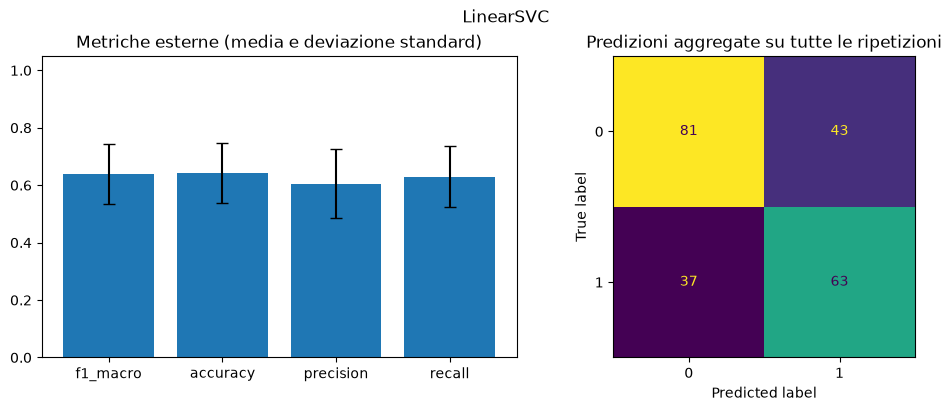

In [2]:
# LinearSVC | set C
# Dataset e pulizia
raw = load_dataset()
X, y, discrete = clean_dataset(raw, "C")

# Preprocessing e modello
factors = (1.0, 1.8, 2.5)
steps = make_preprocessing(
    discrete, min_frequency=2, discrete_imputer=SimpleImputer(strategy='median'),
    native_nan=False, use_smote=bool(factors),
)
# La formulazione primale con squared hinge evita il solver duale di hinge.
model = LinearSVC(loss='squared_hinge', dual=False, tol=1e-3, max_iter=100_000, class_weight='balanced')
pipeline = (ImbPipeline if factors else Pipeline)([*steps, ("model", model)])
param_grid = {'model__C': [0.001, 0.01, 0.1, 1, 10]}

# Validazione e grafici
results_linear_svc, matrix, labels = validate_model(X, y, pipeline, param_grid, factors)
plot_results("LinearSVC", results_linear_svc, matrix, labels)


In [ ]:
# LogisticRegression | set D
# Dataset e pulizia
raw = load_dataset()
X, y, discrete = clean_dataset(raw, "D")

# Preprocessing e modello
factors = (1.0, 1.8, 2.5)
steps = make_preprocessing(
    discrete, min_frequency=2, discrete_imputer=SimpleImputer(strategy="median"),
    native_nan=False, use_smote=bool(factors),
)
model = LogisticRegression(max_iter=10_000, tol=0.001, random_state=RANDOM_STATE, class_weight='balanced')
pipeline = (ImbPipeline if factors else Pipeline)([*steps, ("model", model)])
param_grid = [{'model__C': [0.1, 1, 5], 'model__solver': ['lbfgs'], 'model__l1_ratio': [0]}, {'model__C': [0.1, 1, 5], 'model__solver': ['saga'], 'model__l1_ratio': [0, 0.5, 1]}]

# Validazione e grafici
results_log_reg, matrix, labels = validate_model(X, y, pipeline, param_grid, factors)
plot_results("LogisticRegression", results_log_reg, matrix, labels)


In [ ]:
# RBFSVC | set A
# Dataset e pulizia
raw = load_dataset()
X, y, discrete = clean_dataset(raw, "A")

# Preprocessing e modello
factors = (1.0, 1.5, 1.8)
steps = make_preprocessing(
    discrete, min_frequency=2, discrete_imputer=SimpleImputer(strategy="median"),
    native_nan=False, use_smote=bool(factors),
)
model = SVC(kernel='rbf', class_weight='balanced')
pipeline = (ImbPipeline if factors else Pipeline)([*steps, ("model", model)])
param_grid = {'model__C': [0.1, 1, 10], 'model__gamma': ['scale', 0.01, 0.1, 1]}

# Validazione e grafici
results_rbf_svc, matrix, labels = validate_model(X, y, pipeline, param_grid, factors)
plot_results("RBFSVC", results_rbf_svc, matrix, labels)


Ripetizione 1/2, fold 1/5
Ripetizione 1/2, fold 2/5


c:\Users\lucac\Documents\UNI\2_MAGISTRALE\ANNO_2\Semestre_1\Applied Data Science Project\ADSP_Project\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\lucac\Documents\UNI\2_MAGISTRALE\ANNO_2\Semestre_1\Applied Data Science Project\ADSP_Project\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\lucac\Documents\UNI\2_MAGISTRALE\ANNO_2\Semestre_1\Applied Data Science Project\ADSP_Project\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWar

Ripetizione 1/2, fold 3/5


c:\Users\lucac\Documents\UNI\2_MAGISTRALE\ANNO_2\Semestre_1\Applied Data Science Project\ADSP_Project\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Ripetizione 1/2, fold 4/5
Ripetizione 1/2, fold 5/5
Ripetizione 2/2, fold 1/5
Ripetizione 2/2, fold 2/5
Ripetizione 2/2, fold 3/5
Ripetizione 2/2, fold 4/5
Ripetizione 2/2, fold 5/5


,mean,std
f1_macro,0.6101,0.0887
accuracy,0.6427,0.0865
precision,0.6983,0.1917
recall,0.4100,0.1101


,ripetizione,fold,f1_macro,accuracy,precision,recall
0,1,1,0.6538,0.6957,0.8000,0.4
1,1,2,0.5068,0.5217,0.4444,0.4
2,1,3,0.5087,0.5909,0.6667,0.2
3,1,4,0.6857,0.7273,1.0000,0.4
4,1,5,0.5832,0.5909,0.5556,0.5
5,2,1,0.7527,0.7826,1.0000,0.5
6,2,2,0.5548,0.6087,0.6000,0.3
7,2,3,0.6071,0.6364,0.6667,0.4
8,2,4,0.7179,0.7273,0.7500,0.6
9,2,5,0.5299,0.5455,0.5000,0.4


Migliori parametri per fold


,ripetizione,fold,n_neighbors,p,weights,SMOTENC: fattore,SMOTENC: random_state
0,1,1,7,2,uniform,1.5,42
1,1,2,5,2,uniform,1.0,43
2,1,3,5,1,uniform,1.5,44
3,1,4,5,1,uniform,1.5,45
4,1,5,3,1,uniform,1.0,46
5,2,1,5,1,uniform,1.0,47
6,2,2,11,2,uniform,1.5,48
7,2,3,11,2,uniform,1.5,49
8,2,4,5,2,uniform,1.0,50
9,2,5,11,2,uniform,1.5,51


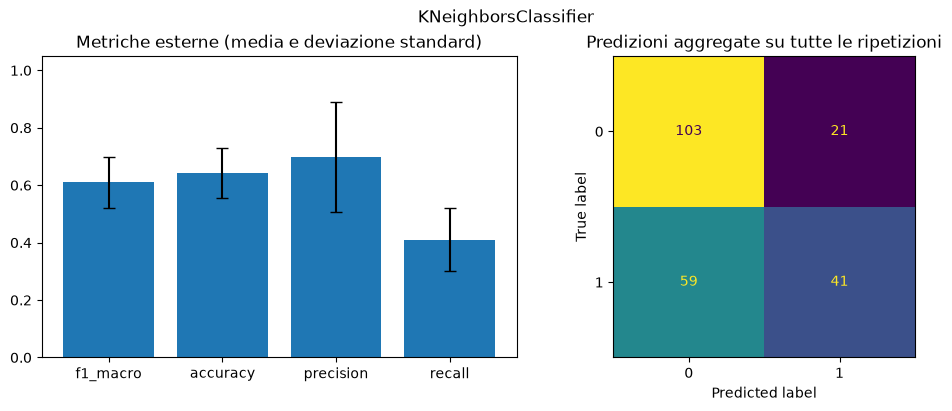

In [5]:
# KNeighborsClassifier | set A
# Dataset e pulizia
raw = load_dataset()
X, y, discrete = clean_dataset(raw, "A")

# Preprocessing e modello
factors = (1.0, 1.5)  # Riferimento senza ricampionamento e +50% per classe.
steps = make_preprocessing(
    discrete, min_frequency=2, discrete_imputer=SimpleImputer(strategy="median"),
    native_nan=False, use_smote=True,
)
model = KNeighborsClassifier()
pipeline = ImbPipeline([*steps, ("model", model)])
param_grid = {'model__n_neighbors': [3, 5, 7, 11], 'model__weights': ['uniform', 'distance'], 'model__p': [1, 2]}

# Validazione e grafici
results_knn, matrix, labels = validate_model(X, y, pipeline, param_grid, factors)
plot_results("KNeighborsClassifier", results_knn, matrix, labels)


Ripetizione 1/2, fold 1/5
Ripetizione 1/2, fold 2/5


c:\Users\lucac\Documents\UNI\2_MAGISTRALE\ANNO_2\Semestre_1\Applied Data Science Project\ADSP_Project\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\lucac\Documents\UNI\2_MAGISTRALE\ANNO_2\Semestre_1\Applied Data Science Project\ADSP_Project\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\lucac\Documents\UNI\2_MAGISTRALE\ANNO_2\Semestre_1\Applied Data Science Project\ADSP_Project\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWar

Ripetizione 1/2, fold 3/5
Ripetizione 1/2, fold 4/5
Ripetizione 1/2, fold 5/5
Ripetizione 2/2, fold 1/5
Ripetizione 2/2, fold 2/5
Ripetizione 2/2, fold 3/5
Ripetizione 2/2, fold 4/5
Ripetizione 2/2, fold 5/5


,mean,std
f1_macro,0.5462,0.0806
accuracy,0.5626,0.0835
precision,0.5315,0.0969
recall,0.4700,0.1059


,ripetizione,fold,f1_macro,accuracy,precision,recall
0,1,1,0.6167,0.6522,0.6667,0.4
1,1,2,0.3808,0.3913,0.3750,0.6
2,1,3,0.5448,0.5909,0.6000,0.3
3,1,4,0.5832,0.5909,0.5556,0.5
4,1,5,0.6333,0.6364,0.6000,0.6
5,2,1,0.6349,0.6522,0.6250,0.5
6,2,2,0.4868,0.5217,0.4286,0.3
7,2,3,0.4990,0.5000,0.4545,0.5
8,2,4,0.5832,0.5909,0.5556,0.5
9,2,5,0.4990,0.5000,0.4545,0.5


Migliori parametri per fold


,ripetizione,fold,max_depth,max_features,min_samples_leaf,n_estimators,SMOTENC: fattore,SMOTENC: random_state
0,1,1,NaN,sqrt,2,100,1.0,42
1,1,2,5.0,log2,2,500,1.8,43
2,1,3,5.0,log2,1,100,1.8,44
3,1,4,NaN,sqrt,2,500,1.5,45
4,1,5,NaN,sqrt,1,100,1.8,46
5,2,1,NaN,log2,1,100,1.0,47
6,2,2,NaN,sqrt,2,500,1.5,48
7,2,3,5.0,sqrt,1,500,1.5,49
8,2,4,5.0,log2,1,100,1.5,50
9,2,5,NaN,log2,1,100,1.8,51


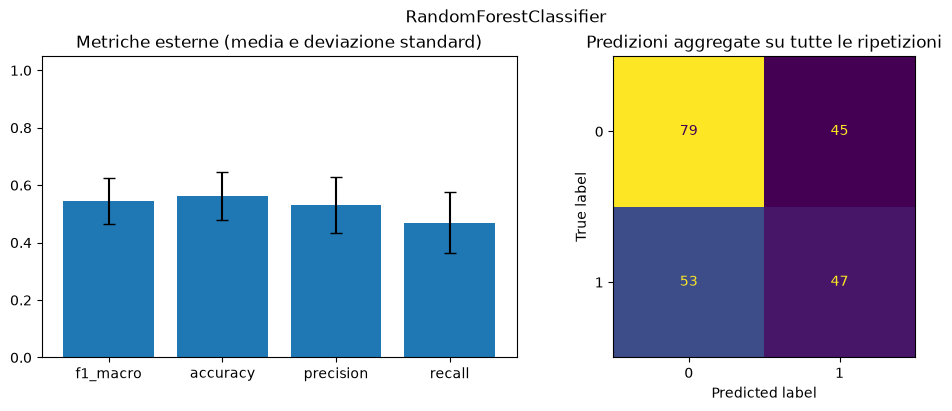

In [4]:
# RandomForestClassifier | set B
# Dataset e pulizia
raw = load_dataset()
X, y, discrete = clean_dataset(raw, "B")

# Preprocessing e modello
factors = (1.0, 1.5, 1.8)
steps = make_preprocessing(
    discrete, min_frequency=2, discrete_imputer=SimpleImputer(strategy="median"),
    native_nan=False, use_smote=bool(factors),
)
model = RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE)
pipeline = (ImbPipeline if factors else Pipeline)([*steps, ("model", model)])
param_grid = {'model__n_estimators': [100, 500], 'model__max_depth': [None, 5], 'model__min_samples_leaf': [1, 2], 'model__max_features': ['sqrt', 'log2']}

# Validazione e grafici
results_rf, matrix, labels = validate_model(X, y, pipeline, param_grid, factors)
plot_results("RandomForestClassifier", results_rf, matrix, labels)


In [ ]:
# XGBClassifier | set D
# Dataset e pulizia
raw = load_dataset()
X, y, discrete = clean_dataset(raw, "D")

# Preprocessing e modello
factors = (1.0, 1.5, 1.8)
steps = make_preprocessing(
    discrete, min_frequency=2, discrete_imputer=SimpleImputer(strategy="median"),
    native_nan=False, use_smote=True,
)
model = XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=1)
pipeline = (ImbPipeline if factors else Pipeline)([*steps, ("model", model)])
param_grid = {'model__n_estimators': [50, 100], 'model__max_depth': [2, 3], 'model__learning_rate': [0.05, 0.1], 'model__min_child_weight': [1, 3, 5]}

# Validazione e grafici
results_xgb, matrix, labels = validate_model(X, y, pipeline, param_grid, factors)
plot_results("XGBClassifier", results_xgb, matrix, labels)


# RISULTATI
- LinearSVC:
- Logistic Regression:
- RBFSVC: 
- XGBoost:
- KNClassifier: